In [1]:
# Execution timing
import time
from datetime import datetime
startTime = time.time()

In [2]:
## Load h2o and prerequisites libraries
import h2o
import numpy as np
import pandas as pd
from h2o.estimators import H2OExtendedIsolationForestEstimator, H2OGradientBoostingEstimator
import warnings
import json

import config

In [3]:
h2o.init(nthreads=-1, min_mem_size= config.min_memory, max_mem_size= config.max_memory, enable_assertions=False)
warnings.filterwarnings('ignore')
# Clear h2o memory
h2o.remove_all()

Checking whether there is an H2O instance running at http://localhost:54321 ..... not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "1.8.0_352"; OpenJDK Runtime Environment (build 1.8.0_352-8u352-ga-1~22.04-b08); OpenJDK 64-Bit Server VM (build 25.352-b08, mixed mode)
  Starting server from /usr/local/lib/python3.10/dist-packages/h2o/backend/bin/h2o.jar
  Ice root: /tmp/tmpz2a_m30k
  JVM stdout: /tmp/tmpz2a_m30k/h2o_randleknight_started_from_python.out
  JVM stderr: /tmp/tmpz2a_m30k/h2o_randleknight_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,02 secs
H2O_cluster_timezone:,Etc/UTC
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.38.0.4
H2O_cluster_version_age:,"1 year, 1 month and 3 days !!!"
H2O_cluster_name:,H2O_from_python_randleknight_ynvvl0
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,28.19 Gb
H2O_cluster_total_cores:,2
H2O_cluster_allowed_cores:,2
H2O_cluster_status:,"locked, healthy"


In [4]:
# Move to DB connection stub
import pyodbc # import oracledb

# Check lims dsn connection to database before proceeding
def get_lims_connection():
    global odbcLimsConnection
    # odbcLimsConnection = oracledb.connect(user=config.limsdb_username, password=config.limsdb_password,
    # dsn=config.limsdb_dsn)
    odbcLimsConnection = pyodbc.connect('DRIVER=' + config.limsdb_driver + ';DATABASE=' + config.limsdb_database +
                                        ';UID=' + config.limsdb_username + ';PWD=' + config.limsdb_password +
                                        ';SERVER=' + config.limsdb_hostname + ';PORT=' + config.limsdb_port +
                                        ';Trusted_Connection=yes')
    return odbcLimsConnection


if __name__ == '__main__':
    try:  # GET THE CONNECTION OBJECT (ENGINE) FOR THE DATABASE
        get_lims_connection()
    except Exception as error:
        exit("Connection could not be made due to the following error: \n", error)


# Check mlar dsn connection to database before proceeding
def get_mlar_connection():
    global odbcMlarConnection
    # odbcMlarConnection = oracledb.connect(user=config.mlardb_username, password=config.mlardb_password,
    # dsn=config.mlardb_dsn)
    odbcMlarConnection = pyodbc.connect('DRIVER=' + config.mlardb_driver + ';DATABASE=' + config.mlardb_database +
                                        ';UID=' + config.mlardb_username + ';PWD=' + config.mlardb_password +
                                        ';SERVER=' + config.mlardb_hostname + ';PORT=' + config.mlardb_port +
                                        ';Trusted_Connection=yes')
    return odbcMlarConnection


if __name__ == '__main__':
    try:
        # GET THE CONNECTION OBJECT (ENGINE) FOR THE DATABASE
        get_mlar_connection()
    except Exception as error:
        exit("Connection could not be made due to the following error: \n", error)


In [5]:
# Start and Finish Logs - MOVE TO CONFIG
sql_command = "select MIN(AUDIT_TIMESTAMP),MAX(AUDIT_TIMESTAMP) from SAMPLE_AUDIT_DECRYPT"
with odbcLimsConnection.cursor() as lims_cursor_fetch_one:
    lims_cursor_fetch_one.execute(sql_command)
    response = lims_cursor_fetch_one.fetchone()
startLog = response[0]
endLog = response[1]

In [6]:
# Execution timing
endTime = time.time()
elapsedTime = endTime - startTime
now = datetime.now()
logEntry = "DateTime: " + str(now) + ", Start: " + str(startLog) + ", End: " + str(endLog) + ", Sample Audit, " \
          "Prerequisite Load End Time = " + str(elapsedTime)   
with open ("executionlog.txt", "a") as writer:
    writer.write('\n'+logEntry)
    writer.close()
    print(logEntry)

DateTime: 2024-02-08 22:56:14.532489, Start: 2023-09-06 18:20:12, End: 2023-09-07 04:32:46, Sample Audit, Prerequisite Load End Time = 10.760231256484985


In [7]:
# Query data and load into dataframe
# bulk union needs to applied for all audit tables
column_names = ['mlar_type', 'audit_action', 'audit_timestamp', 'audit_type', 'audit_counter', 'trans_order',
                'table_name', 'table_key', 'reason', 'record_signed', 'user_name', 'user_role', 'parent_table',
                'parent_key', 'batch_name', 'col_num', 'document_number', 'experiment_number', 'row_num',
                'workbook_number', 'worksheet', 'formulation', 'investigation', 'order_num', 'project_name', 'name',
                'report_number', 'sample_number', 'location_number', 't_mlar', 't_mlar_severity', 'trans_string']
sql_command = "select 'sample_audit_log',action,audit_timestamp,audit_type,counter,trans_order,table_name,table_key," \
              "reason,record_signed,user_name,user_role,'','','',NULL,NULL,NULL,NULL,NULL,'','','','','','',''," \
              "sample_number,'',t_mlar,t_mlar_severity,trans_string from SAMPLE_AUDIT_DECRYPT where audit_timestamp " \
              "between '" + str(startLog) + "' and '" + str(endLog) + "'"

with odbcMlarConnection.cursor() as mlar_cursor_fetch_all:
    mlar_cursor_fetch_all.execute(sql_command)
    queryFetch = mlar_cursor_fetch_all.fetchall()
    
dataFrame = pd.DataFrame.from_records(queryFetch, columns=column_names)

In [8]:
# Execution timing
endTime = time.time()
elapsedTime = endTime - startTime
now = datetime.now()
logEntry = "DateTime: " + str(now) + ", Start: " + str(startLog) + ", End: " + str(endLog) + ", Sample Audit, " \
           "Query end Time = " + str(elapsedTime)
with open ("executionlog.txt", "a") as writer:
    writer.write('\n'+logEntry)
    writer.close()
    print(logEntry)

DateTime: 2024-02-08 22:56:39.537844, Start: 2023-09-06 18:20:12, End: 2023-09-07 04:32:46, Sample Audit, Query end Time = 35.76547074317932


In [9]:
# Retrieve datatypes for training Dataframe
# "string" | "float" | "real" | "double" | "int" | "long" | "numeric" | "categorical" | "factor" | "enum" | "time"
sql_command = "select distinct FIELD_NAME, CASE WHEN FIELD_NAME = 'T_MLAR_SEVERITY' THEN 'categorical' WHEN DATA_TYPE " \
              "in ('Text','Long','List','MultiList','Boolean','File','DBFile','Interval','DateTime','Date') THEN " \
              "'string' WHEN DATA_TYPE in ('Integer','Number') THEN 'numeric' ELSE DATA_TYPE END AS DATATYPE from " \
              "FIELD_MASTER where TABLE_NAME in ('SAMPLE_AUDIT_LOG','SAMPLE','TEST','RESULT') order by FIELD_NAME"

with odbcLimsConnection.cursor() as lims_cursor_fetch_all:
    lims_cursor_fetch_all.execute(sql_command)
    queryFetch = lims_cursor_fetch_all.fetchall()
    
fieldDict = queryFetch

In [10]:
# Convert JSON field to JSON
# dataFrame['trans_string'].to_json(path_or_buf="audit.json", orient="records")
#with open("audit.json") as jsonEntries:
#    jsonDataFrame = json.load(jsonEntries)
dataFrame['trans_string'].apply(json.loads).to_json(path_or_buf="audit.json", orient="records")
with open("audit.json") as jsonEntries:
    jsonDataFrame = json.load(jsonEntries)
jsonDataFrame = pd.json_normalize(jsonDataFrame)

In [11]:
# Convert column datatypes to dictionary
fieldDictDF = pd.DataFrame.from_records(fieldDict)
fieldDictDF.set_index(0, inplace=True)
fieldDict = fieldDictDF[1].to_dict()

In [12]:
# Drop unnecessary or duplicated columns, replace NaN values and comma-replacement character
dataFrame = dataFrame.drop(columns=['trans_string'])
# jsonDataFrame = jsonDataFrame.drop(columns=['SAMPLE_NUMBER']).replace(np.nan,-999).replace("▄",",",regex=True)
jsonDataFrame = jsonDataFrame.replace(np.nan, "█").replace("▄", ",", regex=True)
encodedDataFrame = pd.concat([dataFrame, jsonDataFrame], axis=1)
unsupervisedFeatures = list(encodedDataFrame.drop(columns=['t_mlar', 't_mlar_severity']).columns.values) 


In [13]:
# Set hyperparameters MOVE TO CONFIG APPLY GRID SEARCH
numRecords = int(round(len(encodedDataFrame.index)))
numRecordColumn = int(round(len(encodedDataFrame.columns)))
sampleSize = 256  
numTrees = 100
maxDepth = 20  
numFolds = 2

In [14]:
# Execution timing
endTime = time.time()
elapsedTime = endTime - startTime
now = datetime.now()
logEntry = "DateTime: " + str(now) + ", Start: " + str(startLog) + ", End: " + str(endLog) + ", Sample Audit," \
    "json convert Time = " + str(elapsedTime)
with open ("executionlog.txt", "a") as writer:
    writer.write('\n'+logEntry)
    writer.close()
    print(logEntry)

DateTime: 2024-02-08 22:56:42.984458, Start: 2023-09-06 18:20:12, End: 2023-09-07 04:32:46, Sample Audit,json convert Time = 39.21221923828125


In [15]:
# Define datatypes and convert to H2oFrame
fieldDictUnsupervised = dict(filter(lambda item: item[0] in unsupervisedFeatures, fieldDict.items()))
unsupervisedH2oFrame = h2o.H2OFrame(python_obj=encodedDataFrame, column_types=fieldDictUnsupervised)

# filter dataFrame by T_MLAR = T, if empty do not train supervised model
if (encodedDataFrame['t_mlar'] == "T").shape[0] > 0:
    supervisedFeatures = list(encodedDataFrame.columns.values)
    fieldDictSupervised = dict(filter(lambda item: item[0] in supervisedFeatures, fieldDict.items()))
    focus_column = "t_mlar_severity"
    supervisedH2oFrame = h2o.H2OFrame(python_obj=encodedDataFrame, column_types=fieldDictSupervised)
    skipSupervisedTraining = False
else:
    skipSupervisedTraining = True

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


In [16]:
# RULES ENGINE
#'Retrieve user-defined detection settings'
# General settings
column_names = ['filter_logged_samps', 'filter_cancelled_samps', 'auto_assign_sev', 'auto_severity']
sql_command = "select filter_logged_samps, filter_cancelled_samps, auto_assign_sev, auto_severity " \
              "from T_MLAR_SETTING"
lims_cursor_fetch_all.execute(sql_command)
queryFetch = lims_cursor_fetch_all.fetchall()
generalSettings = pd.DataFrame.from_records(queryFetch, columns=column_names)

In [17]:
# Granular customisable settings
column_names = ['Name', 'auto_assign_sev', 'TABLE1', 'FIELD1', 'OPERATION', 'TABLE2', 'FIELD2', 'SEVERITY']
sql_command = "select tas.NAME, tas.AUTO_ASSIGN_SEV, tasp.TABLE1, tasp.FIELD1, tasp.OPERATION, tasp.TABLE2, " \
              "tasp.FIELD2, tasp.SEVERITY from T_MLAR_SETTING tas " \
              "inner join T_MLAR_SETTING_PARAM tasp on tas.NAME = tasp.T_MLAR_SETTING "
lims_cursor_fetch_all.execute(sql_command)
queryFetch = lims_cursor_fetch_all.fetchall()
granularSettings = pd.DataFrame.from_records(queryFetch, columns=column_names)

In [18]:
# Execution timing
endTime = time.time()
elapsedTime = endTime - startTime
now = datetime.now()
logEntry = "DateTime: " + str(now) + ", Start: " + str(startLog) + ", End: " + str(endLog) + ", Sample Audit," \
    "Apply Detection Settings Time = " + str(elapsedTime)
with open ("executionlog.txt", "a") as writer:
    writer.write('\n'+logEntry)
    writer.close()
    print(logEntry)

DateTime: 2024-02-08 22:57:26.951933, Start: 2023-09-06 18:20:12, End: 2023-09-07 04:32:46, Sample Audit,Apply Detection Settings Time = 83.17969465255737


In [19]:
# Split into Training and Test Unsupervised Frames
# unsupervisedH2oFrameTrain, unsupervisedH2oFrameTest = unsupervisedH2oFrame.split_frame(ratios=[.8], seed=1234)

if skipSupervisedTraining == False:
    supervisedH2oFrameTrain, supervisedH2oFrameTest = supervisedH2oFrame.split_frame(ratios=[.7], seed=1234)

In [20]:
#supervisedH2oFrameTrain["t_mlar_severity"].summary()

In [21]:
#supervisedH2oFrameTest["t_mlar_severity"].summary()

In [22]:
# Train Unsupervised and Supervised model
unsupervisedModel = H2OExtendedIsolationForestEstimator(model_id="unsupervisedModel.hex", ntrees=numTrees,
                                                        ignore_const_cols=True, sample_size=sampleSize, seed=1234)
unsupervisedModel.train(x=unsupervisedFeatures, training_frame=unsupervisedH2oFrame) ##unsupervisedH2oFrameTrain
h2o.save_model(model=unsupervisedModel, path="tmp/unsupervised", force=True)
h2o.download_model(model=unsupervisedModel, path="Download")

if skipSupervisedTraining == False:
    supervisedModel = H2OGradientBoostingEstimator(model_id="supervisedModel.hex", balance_classes = True, 
                                               class_sampling_factors=[0.06, 1.0, 1.0, 1.0, 1.0, 1.0] , 
                                               ntrees=numTrees, max_depth=maxDepth, nfolds=numFolds)
    supervisedModel.train(x=supervisedFeatures, y=focus_column, training_frame=supervisedH2oFrameTrain, validation_frame=supervisedH2oFrameTest)
    h2o.save_model(model=supervisedModel, path="tmp/supervised", force=True)
    h2o.download_model(model=supervisedModel, path="Download")


extendedisolationforest Model Build progress: |██████████████████████████████████| (done) 100%
gbm Model Build progress: |██████████████████████████████████████████████████████| (done) 100%


In [23]:
# Execution timing
endTime = time.time()
elapsedTime = endTime - startTime
now = datetime.now()
logEntry = "DateTime: " + str(now) + ", Start: " + str(startLog) + ", End: " + str(endLog) + ", Sample Audit," \
    "Model Train Time = " + str(elapsedTime)
with open ("executionlog.txt", "a") as writer:
    writer.write('\n'+logEntry)
    writer.close()
    print(logEntry)

DateTime: 2024-02-08 22:59:17.962743, Start: 2023-09-06 18:20:12, End: 2023-09-07 04:32:46, Sample Audit,Model Train Time = 194.1905026435852


extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
gbm prediction progress: |███████████████████████████████████████████████████████| (done) 100%


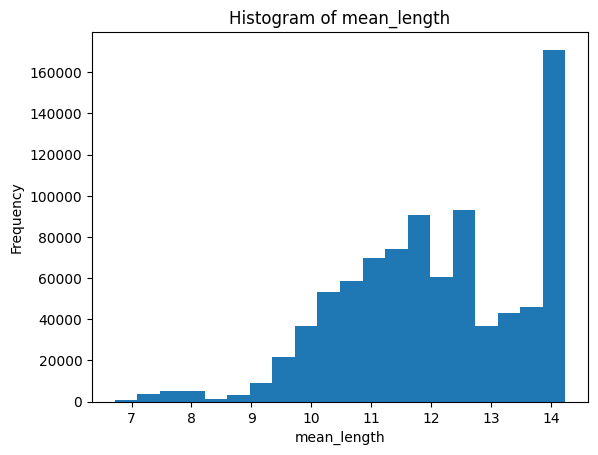

breaks,counts,mids_true,mids,widths
6.52836,nan,nan,nan,nan
6.90475,902,3.07599,6.71656,0.376389
7.28114,3826,3.26487,7.09294,0.376389
7.65753,5151,3.45277,7.46933,0.376389
8.03392,5010,3.64058,7.84572,0.376389
8.41031,1190,3.83007,8.22211,0.376389
8.7867,3074,4.02664,8.5985,0.376389
9.16309,8819,4.20613,8.97489,0.376389
9.53947,21827,4.39345,9.35128,0.376389
9.91586,36662,4.58168,9.72767,0.376389


In [24]:
# Add new scores and anomaly columns to dataTable
predictUnsupervised = unsupervisedModel.predict(unsupervisedH2oFrame)

if skipSupervisedTraining == False: #!!!!Set to True to skip to complete run
    predictSupervised = supervisedModel.predict(supervisedH2oFrameTest).cbind(0) # Dummy column to allow rbind
    predictSupervised = predictSupervised.cbind(supervisedH2oFrameTest[unsupervisedFeatures])

df = predictUnsupervised["mean_length"]
predictUnsupervised["mean_length"].hist(save_plot_path='hist.png')

In [25]:
# Set mean_length value for unsupervised
anomalies = unsupervisedH2oFrame[predictUnsupervised["mean_length"] < 8.0]
exportedH2oFrame = unsupervisedModel.predict(anomalies)["mean_length"].cbind(anomalies[unsupervisedFeatures])
exportedH2oFrame = unsupervisedModel.predict(anomalies)["anomaly_score"].cbind(exportedH2oFrame)
rowCount = exportedH2oFrame.nrows
detectionMethod = np.full((rowCount, 1), 'unsupervised')
detectionFrame = h2o.H2OFrame(detectionMethod)
exportedH2oFrame = exportedH2oFrame.cbind(detectionFrame)

extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
extendedisolationforest prediction progress: |███████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


In [26]:
# Troubleshooting
# h2o.export_file(exportedH2oFrame, path="exportedH2oFrame.csv", format="csv")
# h2o.export_file(detectionFrame, path="detectionFrame.csv", format="csv")


In [27]:
# Combine unsupervised and supervised anomalies
if skipSupervisedTraining == False: #!!!!Set to True to skip to complete run
    rowCount = predictSupervised.nrows
    detectionMethod = np.full((rowCount, 1), 'supervised')
    detectionFrame = h2o.H2OFrame(detectionMethod)
    predictSupervised.set_name("predict","anomaly_score") # renaming columns to allow rbind
    predictSupervised.set_name("0.0","mean_length") # renaming columns to allow rbind
    predictSupervised = predictSupervised.cbind(detectionFrame)
    exportedH2oFrame = exportedH2oFrame.rbind(predictSupervised)

    
exportedH2oFrame.set_name("anomaly_score","anomaly_score_prediction")    
exportedH2oFrame.set_name("C1", "detection_method") 

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


In [28]:
# Execution timing
endTime = time.time()
elapsedTime = endTime - startTime
now = datetime.now()
logEntry = "DateTime: " + str(now) + ", Start: " + str(startLog) + ", End: " + str(endLog) + ", Sample Audit," \
    "Predict Time = " + str(elapsedTime)
with open ("executionlog.txt", "a") as writer:
    writer.write('\n'+logEntry)
    writer.close()
    print(logEntry)

DateTime: 2024-02-08 23:00:03.280245, Start: 2023-09-06 18:20:12, End: 2023-09-07 04:32:46, Sample Audit,Predict Time = 239.5079915523529


In [29]:
## Query current log count
cursor = odbcLimsConnection.cursor()
sql_command = "select MAX(COUNTER) from " + config.outputTable
cursor.execute(sql_command)
response = cursor.fetchone()
counter = response[0]

## Depending on the value, default either to 1 if empty or add 1 for next insert sequence
if counter is None:
    id_number = 1
else:
    id_number = counter + 1

In [30]:
## Define export columns for final df prior to SQL write
finalDataFrame = exportedH2oFrame
exportCols = ['mlar_type', 'audit_counter', 'audit_type', 'audit_action', 'table_name', 'table_key',
              'parent_table', 'parent_key', 'experiment_number', 'document_number',  'sample_number',
              'audit_timestamp', 'user_name', 'detection_method', 'mean_length', 'anomaly_score_prediction']
finalDataFrame = finalDataFrame[exportCols]

In [31]:
## Prepare dataframe for sql insertion
rowCount = finalDataFrame.nrows
anomalyData = np.full((rowCount, 1), 'F')
anomalyFrame = h2o.H2OFrame(anomalyData)
counterData = (id_number) + np.arange(finalDataFrame.shape[0])
counterFrame = h2o.H2OFrame(counterData)
syncedData = np.full((rowCount, 1), 'F')
syncedFrame = h2o.H2OFrame(syncedData)
finalDataFrame = finalDataFrame.cbind(counterFrame)
finalDataFrame.set_name("C1", "counter")
finalDataFrame = finalDataFrame.cbind(anomalyFrame)
finalDataFrame.set_name("C1", "reviewed")
finalDataFrame = finalDataFrame.cbind(syncedFrame)
finalDataFrame.set_name("C1", "synced")

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


In [32]:
## Convert to panda dataframe
finalDataFrame = finalDataFrame.as_data_frame(use_pandas=True)
finalDataFrame['audit_timestamp'] = pd.to_datetime(finalDataFrame['audit_timestamp'], unit='ms')
finalDataFrame.rename(columns={'table_name': 'audit_table_name', 'table_key':'audit_table_key'}, inplace=True)
finalDataFrame.replace('', 'No Data', regex=True)
finalDataFrame.fillna('No Data', inplace=True)

In [33]:
# Troubleshooting
#finalDataFrame

In [34]:
# Sql insertion of anomalies
for index, row in finalDataFrame.iterrows():
    cursor.execute("INSERT INTO T_MLAR_LOG (COUNTER,MLAR_TYPE,AUDIT_TABLE_NAME,AUDIT_TABLE_KEY,AUDIT_ACTION,"
                   "AUDIT_COUNTER,AUDIT_TYPE,REVIEWED,AUDIT_TIMESTAMP,USER_NAME,DETECTION_METHOD,MEAN_LENGTH,"
                   "AUDIT_MAIN_ID,SYNCED,METRIC) VALUES(?,?,?,?,?,?,?,?,?,?,?,?,?,?,?)"
                   , row.counter, row.mlar_type, row.audit_table_name, row.audit_table_key, row.audit_action,
                   row.audit_counter, row.audit_type, row.reviewed, row.audit_timestamp,  row.user_name,
                   row.detection_method, row.mean_length, row.sample_number, row.synced,
                   row.anomaly_score_prediction)

In [35]:
## Oracle handling
#rows = finalDataFrame.to_numpy().tolist()

#sql_command = """INSERT INTO """ + outputTable + """ (MLAR_TYPE, AUDIT_COUNTER, AUDIT_TYPE, AUDIT_ACTION, AUDIT_TABLE_NAME, AUDIT_TABLE_KEY, AUDIT_PARENT_TABLE, AUDIT_PARENT_KEY, AUDIT_EXP_NUMBER, AUDIT_DOC_NUMBER,  AUDIT_MAIN_ID, AUDIT_TIMESTAMP, USER_NAME, DETECTION_METHOD, MEAN_LENGTH, ANOMALY_SCORE, COUNTER, REVIEWED, SYNCED) VALUES (:1, :2, :3, :4, :5, :6, :7, :8, :9, :10, :11, :12, :13 ,:14, :15, :16, :17, :18, :19)"""
#cursor.prepare(sql_command)
#cursor.executemany(sql_command, rows)

In [36]:
odbcLimsConnection.commit()
cursor.close()

## Clear h2o memory
h2o.remove_all()
h2o.cluster().shutdown()

H2O session _sid_9d81 closed.


In [37]:
# Execution timing
endTime = time.time()
elapsedTime = endTime - startTime
now = datetime.now()
logEntry = "DateTime: " + str(now) + ", Start: " + str(startLog) + ", End: " + str(endLog) + ", Sample Audit," \
    "Completion Time = " + str(elapsedTime)
with open ("executionlog.txt", "a") as writer:
    writer.write('\n'+logEntry)
    writer.close()
    print(logEntry)

DateTime: 2024-02-08 23:03:36.893029, Start: 2023-09-06 18:20:12, End: 2023-09-07 04:32:46, Sample Audit,Completion Time = 453.12078762054443
